# DICOM rendering and exploratory features

Deterministic grayscale rendering, synchronized bounding-box geometry, and training-only image feature analysis.


### Method sources

- DICOM PS3.3: [Pixel Padding Value and Range Limit](https://dicom.nema.org/medical/dicom/2022c/output/chtml/part03/sect_C.7.5.html)
- pydicom: [Modality/VOI order](https://pydicom.github.io/pydicom/dev/reference/generated/pydicom.pixels.apply_voi_lut.html)
- pydicom: [Presentation LUT](https://pydicom.github.io/pydicom/3.0/reference/generated/pydicom.pixels.apply_presentation_lut.html)
- Practical reference: [Mammo-CLIP VinDr preprocessing](https://github.com/batmanlab/Mammo-CLIP/blob/main/src/preprocessing/preprocess_image_to_png_vindr.py) and [Kaggle mammography conversion](https://www.kaggle.com/code/theoviel/dicom-resized-png-jpg)

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import sys
import time
from pathlib import Path

import cv2
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import pydicom
from PIL import Image
from scipy import ndimage, stats
from skimage import feature, filters, measure, morphology
from pydicom.pixels import (
    apply_modality_lut,
    apply_presentation_lut,
    apply_voi_lut,
)

In [ ]:
EXPECTED_PYTHON = Path(os.environ.get("MAMMO_PYTHON", "/home/azyqan/venvs/ml-torch/bin/python")).resolve()
assert Path(sys.executable).resolve() == EXPECTED_PYTHON

import os

_start = Path.cwd().resolve()
PROJECT_ROOT = next(
    candidate for candidate in (_start, *_start.parents)
    if (candidate / "notebooks").is_dir()
    and (candidate / "artifacts").is_dir()
    and (candidate / "dataset").is_dir()
)
DATASET_ROOT = Path(os.environ.get("MAMMO_DATA_ROOT", PROJECT_ROOT / "dataset")).expanduser().resolve()
WORK_DATA_ROOT = Path(os.environ.get("MAMMO_WORK_DATA_ROOT", PROJECT_ROOT / "dataset")).expanduser().resolve()
DICOM_ROOT = DATASET_ROOT / "images_dicom"
if not DICOM_ROOT.is_dir() and (DATASET_ROOT / "images").is_dir():
    DICOM_ROOT = DATASET_ROOT / "images"
ANNOTATIONS = DATASET_ROOT / "annotations"
if not ANNOTATIONS.is_dir():
    ANNOTATIONS = DATASET_ROOT
RAW_DIR = WORK_DATA_ROOT / "Raw"
PROCESSED_DIR = WORK_DATA_ROOT / "Processed"
CONFIG_DIR = PROJECT_ROOT / "dataset" / "protocol"
MODEL_DIR = Path(os.environ.get("MAMMO_MODEL_ROOT", WORK_DATA_ROOT / "checkpoints")).expanduser().resolve()
COHORT_TABLES = PROJECT_ROOT / "dataset"
EDA_TABLES = PROJECT_ROOT / "artifacts" / "eda"
MODEL_TABLES = PROJECT_ROOT / "artifacts" / "models"
FIGURE_ROOT = PROJECT_ROOT / "figures"
FIGURE_INDEX = json.loads((FIGURE_ROOT / "index.json").read_text(encoding="utf-8"))
FIGURE_PATHS = {item["source"]: item["path"] for item in FIGURE_INDEX}

def resolve_figure(relative_path: str) -> Path:
    return PROJECT_ROOT / FIGURE_PATHS.get(relative_path, relative_path)

def protocol_table(name: str) -> Path:
    if name in ["bcrf_checkpoint_lineage.csv","bcrf_deployment_lineage.csv","bcrf_freeze_manifest.csv","frozen_evaluation_input_lineage.csv"]:
        return CONFIG_DIR / name
    return MODEL_TABLES / name

def resolve_dicom(relative_path: str) -> Path:
    name = Path(relative_path).name
    direct = DICOM_ROOT / name
    if direct.is_file():
        return direct
    candidates = list(DICOM_ROOT.rglob(name))
    if len(candidates) != 1:
        raise FileNotFoundError(f"Expected one DICOM for {name}; found {len(candidates)}")
    return candidates[0]

def legacy_relative_path(path: Path) -> str:
    if path.name in ["bcrf_checkpoint_lineage.csv", "bcrf_deployment_lineage.csv", "bcrf_freeze_manifest.csv", "frozen_evaluation_input_lineage.csv"]:
        return "Tables/Models/" + path.name
    if path.is_relative_to(MODEL_DIR):
        return "Models/" + str(path.relative_to(MODEL_DIR))
    if path.is_relative_to(WORK_DATA_ROOT / "Raw"):
        return "Data/Raw/" + str(path.relative_to(WORK_DATA_ROOT / "Raw"))
    if path.is_relative_to(PROCESSED_DIR):
        return "Data/Processed/" + str(path.relative_to(PROCESSED_DIR))
    if path.is_relative_to(CONFIG_DIR):
        return "Config/" + str(path.relative_to(CONFIG_DIR))
    if path.is_relative_to(MODEL_TABLES):
        return "Tables/Models/" + str(path.relative_to(MODEL_TABLES))
    return str(path.relative_to(PROJECT_ROOT))

TABLE_DIR = EDA_TABLES


In [3]:
times_font = Path("/mnt/c/Windows/Fonts/times.ttf")
if times_font.exists():
    font_manager.fontManager.addfont(times_font)

mpl.rcParams.update({
    "font.family": os.environ.get("MAMMO_FONT", "Times New Roman"),
    "font.size": 18,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "figure.titlesize": 20,
    "savefig.bbox": "tight",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})
pydicom.config.settings.reading_validation_mode = pydicom.config.IGNORE

In [4]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


figure_registry = []


def save_figure(fig: plt.Figure, stem: str, source_table: Path | None = None) -> None:
    png_path = resolve_figure("Figures/EDA/" + stem + ".png")
    pdf_path = resolve_figure("Figures/EDA/" + stem + ".pdf")
    fig.savefig(png_path, dpi=350)
    fig.savefig(pdf_path)
    figure_registry.append({
        "figure_id": stem,
        "png_path": str(png_path.relative_to(PROJECT_ROOT)),
        "pdf_path": str(pdf_path.relative_to(PROJECT_ROOT)),
        "png_sha256": sha256_file(png_path),
        "pdf_sha256": sha256_file(pdf_path),
        "source_table": "" if source_table is None else str(source_table.relative_to(PROJECT_ROOT)),
        "dpi": 350,
        "title_font_pt": 20,
        "other_text_pt": 18,
    })

In [ ]:
manifest = pd.read_csv(MANIFEST_PATH, low_memory=False)
acquisition = pd.read_csv(ACQUISITION_PATH, low_memory=False)
splits = pd.read_csv(SPLIT_PATH, low_memory=False)
train_manifest = manifest.loc[manifest.split.eq("train")].copy()

assert len(manifest) == 1622
assert manifest.groupby("study_id").split.nunique().max() == 1
assert set(train_manifest.image_id).isdisjoint(set(manifest.loc[manifest.split.eq("locked_test"), "image_id"]))
assert train_manifest.actual_sha256.notna().all()



In [6]:
def stored_padding_mask(stored_pixels: np.ndarray, ds: pydicom.Dataset) -> np.ndarray:
    if not hasattr(ds, "PixelPaddingValue"):
        return np.zeros(stored_pixels.shape, dtype=bool)

    first = float(ds.PixelPaddingValue)
    second = float(getattr(ds, "PixelPaddingRangeLimit", first))
    lower, upper = sorted((first, second))
    return (stored_pixels >= lower) & (stored_pixels <= upper)

In [7]:
def normalize_valid_pixels(values: np.ndarray, valid_mask: np.ndarray) -> np.ndarray:
    valid_values = values[valid_mask & np.isfinite(values)]
    if valid_values.size == 0:
        raise ValueError("No valid pixels after DICOM transformations")

    lower = float(valid_values.min())
    upper = float(valid_values.max())
    if not upper > lower:
        raise ValueError("Degenerate DICOM display range")

    normalized = np.zeros(values.shape, dtype=np.float32)
    normalized[valid_mask] = np.clip(
        (values[valid_mask] - lower) / (upper - lower),
        0.0,
        1.0,
    ).astype(np.float32)
    return normalized

In [8]:
def standard_dicom_render(path: Path) -> dict:
    ds = pydicom.dcmread(path)
    stored = ds.pixel_array
    padding_mask = stored_padding_mask(stored, ds)
    valid_mask = ~padding_mask

    modality = np.asarray(apply_modality_lut(stored, ds), dtype=np.float64)
    voi = np.asarray(apply_voi_lut(modality, ds, index=0, prefer_lut=True), dtype=np.float64)

    has_presentation_lut = hasattr(ds, "PresentationLUTShape") or hasattr(ds, "PresentationLUTSequence")
    if has_presentation_lut:
        presented = np.asarray(apply_presentation_lut(voi, ds), dtype=np.float64)
        polarity_source = "Presentation LUT"
    elif str(getattr(ds, "PhotometricInterpretation", "")).upper() == "MONOCHROME1":
        valid_values = voi[valid_mask & np.isfinite(voi)]
        presented = valid_values.min() + valid_values.max() - voi
        polarity_source = "MONOCHROME1 fallback"
    else:
        presented = voi
        polarity_source = "MONOCHROME2 identity"

    image = normalize_valid_pixels(presented, valid_mask)
    assert image.dtype == np.float32
    assert np.isfinite(image).all()
    assert 0.0 <= float(image.min()) <= float(image.max()) <= 1.0

    return {
        "dataset": ds,
        "stored": stored,
        "modality": modality,
        "voi": voi,
        "presented": presented,
        "padding_mask": padding_mask,
        "valid_mask": valid_mask,
        "image": image,
        "polarity_source": polarity_source,
    }

In [9]:
def resize_and_pad(
    image: np.ndarray,
    valid_mask: np.ndarray,
    output_size: tuple[int, int] = (1024, 1024),
) -> tuple[np.ndarray, np.ndarray, dict]:
    source_height, source_width = image.shape
    output_height, output_width = output_size
    scale = min(output_height / source_height, output_width / source_width)
    resized_height = int(round(source_height * scale))
    resized_width = int(round(source_width * scale))
    top = (output_height - resized_height) // 2
    left = (output_width - resized_width) // 2

    resized_image = cv2.resize(image, (resized_width, resized_height), interpolation=cv2.INTER_LINEAR)
    resized_mask = cv2.resize(valid_mask.astype(np.uint8), (resized_width, resized_height), interpolation=cv2.INTER_NEAREST).astype(bool)
    canvas = np.zeros(output_size, dtype=np.float32)
    mask_canvas = np.zeros(output_size, dtype=bool)
    canvas[top:top + resized_height, left:left + resized_width] = resized_image
    mask_canvas[top:top + resized_height, left:left + resized_width] = resized_mask

    transform = {
        "scale": float(scale),
        "top": int(top),
        "left": int(left),
        "source_height": int(source_height),
        "source_width": int(source_width),
        "output_height": int(output_height),
        "output_width": int(output_width),
    }
    return canvas, mask_canvas, transform

In [10]:
def transform_boxes(boxes: np.ndarray, transform: dict) -> np.ndarray:
    mapped = np.asarray(boxes, dtype=np.float32).copy()
    mapped[:, [0, 2]] = mapped[:, [0, 2]] * transform["scale"] + transform["left"]
    mapped[:, [1, 3]] = mapped[:, [1, 3]] * transform["scale"] + transform["top"]
    return mapped


def inverse_transform_boxes(boxes: np.ndarray, transform: dict) -> np.ndarray:
    restored = np.asarray(boxes, dtype=np.float32).copy()
    restored[:, [0, 2]] = (restored[:, [0, 2]] - transform["left"]) / transform["scale"]
    restored[:, [1, 3]] = (restored[:, [1, 3]] - transform["top"]) / transform["scale"]
    return restored


def boxes_from_manifest(row: pd.Series) -> np.ndarray:
    records = json.loads(row.boxes_xyxy_json)
    if not records:
        return np.zeros((0, 4), dtype=np.float32)
    return np.asarray(
        [[item["xmin"], item["ymin"], item["xmax"], item["ymax"]] for item in records],
        dtype=np.float32,
    )

In [11]:
def build_breast_mask(
    image: np.ndarray,
    valid_mask: np.ndarray,
) -> np.ndarray:
    valid_values = image[valid_mask]
    threshold = filters.threshold_otsu(valid_values)
    candidate = valid_mask & (image > threshold)

    minimum_area = max(64, int(0.001 * valid_mask.size))
    candidate = morphology.remove_small_objects(candidate, min_size=minimum_area)
    candidate = morphology.binary_closing(candidate, morphology.disk(5))
    candidate = ndimage.binary_fill_holes(candidate)

    labels = measure.label(candidate)
    regions = measure.regionprops(labels)
    if not regions:
        raise ValueError("Breast mask extraction returned no component")

    largest_label = max(regions, key=lambda region: region.area).label
    breast_mask = labels == largest_label
    return breast_mask.astype(bool)

In [12]:
def masked_cooccurrence_probability(
    quantized: np.ndarray,
    mask: np.ndarray,
    delta_row: int,
    delta_col: int,
    levels: int,
) -> np.ndarray:
    row_a = slice(max(0, -delta_row), quantized.shape[0] - max(0, delta_row))
    row_b = slice(max(0, delta_row), quantized.shape[0] - max(0, -delta_row))
    col_a = slice(max(0, -delta_col), quantized.shape[1] - max(0, delta_col))
    col_b = slice(max(0, delta_col), quantized.shape[1] - max(0, -delta_col))

    pair_mask = mask[row_a, col_a] & mask[row_b, col_b]
    source = quantized[row_a, col_a][pair_mask]
    target = quantized[row_b, col_b][pair_mask]
    counts = np.bincount(
        source * levels + target,
        minlength=levels * levels,
    ).reshape(levels, levels)
    probability = counts + counts.T
    return probability / probability.sum()

In [13]:
def masked_glcm_features(
    image: np.ndarray,
    mask: np.ndarray,
    levels: int = 32,
) -> dict[str, float]:
    quantized = np.clip(np.floor(image * levels), 0, levels - 1).astype(np.int16)
    distances = (1, 4, 8)
    angles = (0.0, np.pi / 4, np.pi / 2, 3 * np.pi / 4)
    indices = np.arange(levels, dtype=np.float64)
    grid_i, grid_j = np.meshgrid(indices, indices, indexing="ij")
    records = []

    for distance in distances:
        for angle in angles:
            delta_row = int(round(distance * np.sin(angle)))
            delta_col = int(round(distance * np.cos(angle)))
            probability = masked_cooccurrence_probability(
                quantized,
                mask,
                delta_row,
                delta_col,
                levels,
            )
            difference = grid_i - grid_j
            mean_i = float((probability * grid_i).sum())
            mean_j = float((probability * grid_j).sum())
            std_i = float(np.sqrt((probability * (grid_i - mean_i) ** 2).sum()))
            std_j = float(np.sqrt((probability * (grid_j - mean_j) ** 2).sum()))
            correlation = float(
                (probability * (grid_i - mean_i) * (grid_j - mean_j)).sum()
                / max(std_i * std_j, np.finfo(float).eps)
            )
            records.append(
                {
                    "contrast": float((probability * difference**2).sum()),
                    "dissimilarity": float((probability * np.abs(difference)).sum()),
                    "homogeneity": float((probability / (1.0 + difference**2)).sum()),
                    "energy": float(np.sqrt((probability**2).sum())),
                    "correlation": correlation,
                }
            )

    frame = pd.DataFrame(records)
    return {f"glcm_{name}": float(frame[name].mean()) for name in frame.columns}

In [14]:
def intensity_texture_features(
    image: np.ndarray,
    breast_mask: np.ndarray,
) -> dict[str, float]:
    values = image[breast_mask].astype(np.float64)
    histogram, _ = np.histogram(values, bins=64, range=(0.0, 1.0))
    probabilities = histogram / histogram.sum()
    nonzero = probabilities[probabilities > 0]

    quantized = np.round(image * 255).astype(np.uint8)
    lbp = feature.local_binary_pattern(quantized, P=8, R=1, method="uniform")
    lbp_histogram, _ = np.histogram(lbp[breast_mask], bins=np.arange(11))
    lbp_probabilities = lbp_histogram / lbp_histogram.sum()
    lbp_nonzero = lbp_probabilities[lbp_probabilities > 0]

    gradient = filters.sobel(image)
    interior_mask = morphology.erosion(breast_mask, morphology.disk(2))
    gradient_values = gradient[interior_mask]

    return {
        "intensity_mean": float(values.mean()),
        "intensity_std": float(values.std(ddof=1)),
        "intensity_iqr": float(np.subtract(*np.percentile(values, [75, 25]))),
        "intensity_skew": float(stats.skew(values, bias=False)),
        "intensity_kurtosis": float(stats.kurtosis(values, bias=False)),
        "intensity_entropy": float(-(nonzero * np.log2(nonzero)).sum()),
        "lbp_entropy": float(-(lbp_nonzero * np.log2(lbp_nonzero)).sum()),
        "lbp_uniformity": float((lbp_probabilities**2).sum()),
        "gradient_mean": float(gradient_values.mean()),
        "gradient_q95": float(np.quantile(gradient_values, 0.95)),
    }

In [15]:
def morphology_features(
    breast_mask: np.ndarray,
    valid_mask: np.ndarray,
    transform: dict,
    ds: pydicom.Dataset,
) -> dict[str, float | str]:
    region = measure.regionprops(measure.label(breast_mask))[0]
    spacing_source = "missing"
    row_spacing = np.nan
    column_spacing = np.nan

    if hasattr(ds, "PixelSpacing"):
        row_spacing, column_spacing = map(float, ds.PixelSpacing)
        spacing_source = "PixelSpacing"
    elif hasattr(ds, "ImagerPixelSpacing"):
        row_spacing, column_spacing = map(float, ds.ImagerPixelSpacing)
        spacing_source = "ImagerPixelSpacing"

    source_area_pixels = float(region.area) / transform["scale"] ** 2
    physical_area = source_area_pixels * row_spacing * column_spacing

    return {
        "breast_area_fraction": float(region.area / valid_mask.sum()),
        "breast_eccentricity": float(region.eccentricity),
        "breast_solidity": float(region.solidity),
        "breast_extent": float(region.extent),
        "breast_perimeter_normalized": float(region.perimeter / np.sqrt(region.area)),
        "breast_axis_ratio": float(region.axis_major_length / max(region.axis_minor_length, 1.0)),
        "row_spacing_mm": float(row_spacing),
        "column_spacing_mm": float(column_spacing),
        "breast_area_mm2": float(physical_area),
        "spacing_source": spacing_source,
    }

In [16]:
def extract_standard_features(row: pd.Series) -> tuple[dict, dict]:
    dicom_path = resolve_dicom(row.relative_dicom_path)
    rendered = standard_dicom_render(dicom_path)
    resized, valid_mask, transform = resize_and_pad(
        rendered["image"],
        rendered["valid_mask"],
        output_size=(512, 512),
    )
    breast_mask = build_breast_mask(resized, valid_mask)

    features = {
        "image_id": row.image_id,
        "study_id": row.study_id,
        "split": row.split,
        "label": int(row.label),
        "manufacturer": row.manufacturer,
        "breast_density": row.breast_density,
        "laterality": row.laterality,
        "view_position": row.view_position,
        "photometric_interpretation": row.photometric_interpretation,
        "bits_stored": int(row.bits_stored),
        "polarity_source": rendered["polarity_source"],
    }
    features.update(intensity_texture_features(resized, breast_mask))
    features.update(masked_glcm_features(resized, breast_mask))
    features.update(
        morphology_features(
            breast_mask,
            valid_mask,
            transform,
            rendered["dataset"],
        )
    )

    artifacts = {
        "rendered": rendered,
        "resized": resized,
        "valid_mask": valid_mask,
        "breast_mask": breast_mask,
        "transform": transform,
    }
    return features, artifacts

In [17]:
train_acquisition = acquisition.merge(
    train_manifest[["image_id", "label", "relative_dicom_path"]],
    on="image_id",
    how="inner",
    validate="one_to_one",
)

def select_representative(mask: pd.Series, excluded: set[str]) -> pd.Series:
    candidates = train_acquisition.loc[mask & ~train_acquisition.image_id.isin(excluded)]
    if candidates.empty:
        raise ValueError("No representative training image for the requested DICOM path")
    return candidates.sort_values("image_id").iloc[0]

representative_rules = {
    "voi_lut_sequence": train_acquisition.voi_lut_sequence_present.eq(True),
    "padding_range": train_acquisition.pixel_padding_range_limit.notna(),
    "monochrome1": train_acquisition.photometric_interpretation.eq("MONOCHROME1"),
    "monochrome2_no_voi_lut": (
        train_acquisition.photometric_interpretation.eq("MONOCHROME2")
        & train_acquisition.voi_lut_sequence_present.eq(False)
    ),
}

selected_rows = []
selected_ids = set()
for rule_name, rule_mask in representative_rules.items():
    selected = select_representative(rule_mask, selected_ids)
    selected_ids.add(selected.image_id)
    selected_rows.append({"rule": rule_name, **selected.to_dict()})

representatives = pd.DataFrame(selected_rows)
assert representatives.image_id.isin(train_manifest.image_id).all()
assert representatives.image_id.nunique() == len(representatives)
display(
    representatives[
        [
            "rule",
            "image_id",
            "photometric_interpretation",
            "voi_lut_sequence_present",
            "pixel_padding_range_limit",
        ]
    ]
)

,rule,image_id,photometric_interpretation,voi_lut_sequence_present,pixel_padding_range_limit
0,voi_lut_sequence,002074412a8fc178c271fb93b55c3e29,MONOCHROME2,True,NaN
1,padding_range,058e5f91678b4d3dac39bf1b6a798a22,MONOCHROME2,False,4204.0
2,monochrome1,001ade2a3cb53fd808bd2856a0df5413,MONOCHROME1,False,NaN
3,monochrome2_no_voi_lut,061bf98fabad5f9d99fb1919346a3a76,MONOCHROME2,False,3424.0


In [18]:
representative_artifacts = {}
unit_checks = []

for item in representatives.itertuples(index=False):
    manifest_row = train_manifest.loc[train_manifest.image_id.eq(item.image_id)].iloc[0]
    features_row, artifacts = extract_standard_features(manifest_row)
    representative_artifacts[item.rule] = artifacts

    image = artifacts["rendered"]["image"]
    transform = artifacts["transform"]
    expected_height = round(transform["source_height"] * transform["scale"])
    expected_width = round(transform["source_width"] * transform["scale"])
    unit_checks.extend(
        [
            {
                "check": f"{item.rule}: finite unit range",
                "passed": bool(np.isfinite(image).all() and image.min() >= 0 and image.max() <= 1),
            },
            {
                "check": f"{item.rule}: aspect-preserving resize",
                "passed": bool(
                    expected_height <= transform["output_height"]
                    and expected_width <= transform["output_width"]
                ),
            },
            {
                "check": f"{item.rule}: non-empty breast mask",
                "passed": bool(artifacts["breast_mask"].sum() > 0),
            },
        ]
    )

In [19]:
padding_artifacts = representative_artifacts["padding_range"]["rendered"]
padding_ds = padding_artifacts["dataset"]
padding_stored = padding_artifacts["stored"]
padding_lower, padding_upper = sorted(
    (float(padding_ds.PixelPaddingValue), float(padding_ds.PixelPaddingRangeLimit))
)
expected_padding = (padding_stored >= padding_lower) & (padding_stored <= padding_upper)
unit_checks.append(
    {
        "check": "stored inclusive padding range",
        "passed": bool(np.array_equal(padding_artifacts["padding_mask"], expected_padding)),
    }
)

In [ ]:
roundtrip_row = train_manifest.loc[train_manifest.n_boxes.gt(0)].iloc[0]
roundtrip_image = standard_dicom_render(
    resolve_dicom(roundtrip_row.relative_dicom_path)
)
_, _, roundtrip_transform = resize_and_pad(
    roundtrip_image["image"],
    roundtrip_image["valid_mask"],
)
source_boxes = boxes_from_manifest(roundtrip_row)
restored_boxes = inverse_transform_boxes(
    transform_boxes(source_boxes, roundtrip_transform),
    roundtrip_transform,
)
unit_checks.append(
    {
        "check": "bbox transform round trip",
        "passed": bool(np.max(np.abs(source_boxes - restored_boxes)) < 1e-3),
    }
)

unit_check_table = pd.DataFrame(unit_checks)
assert unit_check_table.passed.all()


In [21]:
def total_box_area_fraction(row: pd.Series) -> float:
    boxes = boxes_from_manifest(row)
    areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return float(areas.sum() / (row.width * row.height))

preview_candidates = train_manifest.loc[train_manifest.label.eq(1)].copy()
preview_candidates["box_area_fraction"] = preview_candidates.apply(
    total_box_area_fraction,
    axis=1,
)
median_area = preview_candidates.box_area_fraction.median()
preview_index = (preview_candidates.box_area_fraction - median_area).abs().idxmin()
preview_row = preview_candidates.loc[preview_index]
preview_features, preview_artifacts = extract_standard_features(preview_row)

preview_source_path = TABLE_DIR / "standard_render_preview_source.csv"
pd.DataFrame(
    [
        {
            "image_id": preview_row.image_id,
            "study_id": preview_row.study_id,
            "split": preview_row.split,
            "selection_rule": "training target closest to median total bbox area fraction",
            "box_area_fraction": preview_row.box_area_fraction,
            "actual_sha256": preview_row.actual_sha256,
        }
    ]
).to_csv(preview_source_path, index=False)

display(pd.read_csv(preview_source_path))

,image_id,study_id,split,selection_rule,box_area_fraction,actual_sha256
0,9f65a2368a5df60f1910d687067ced3b,9c8e8f688e99a35f6bb0a78cd4ae8d7e,train,training target closest to median total bbox a...,0.004565,0880767dd8e9cc621b9222bfd9d4c8907cec0e75dfb008...


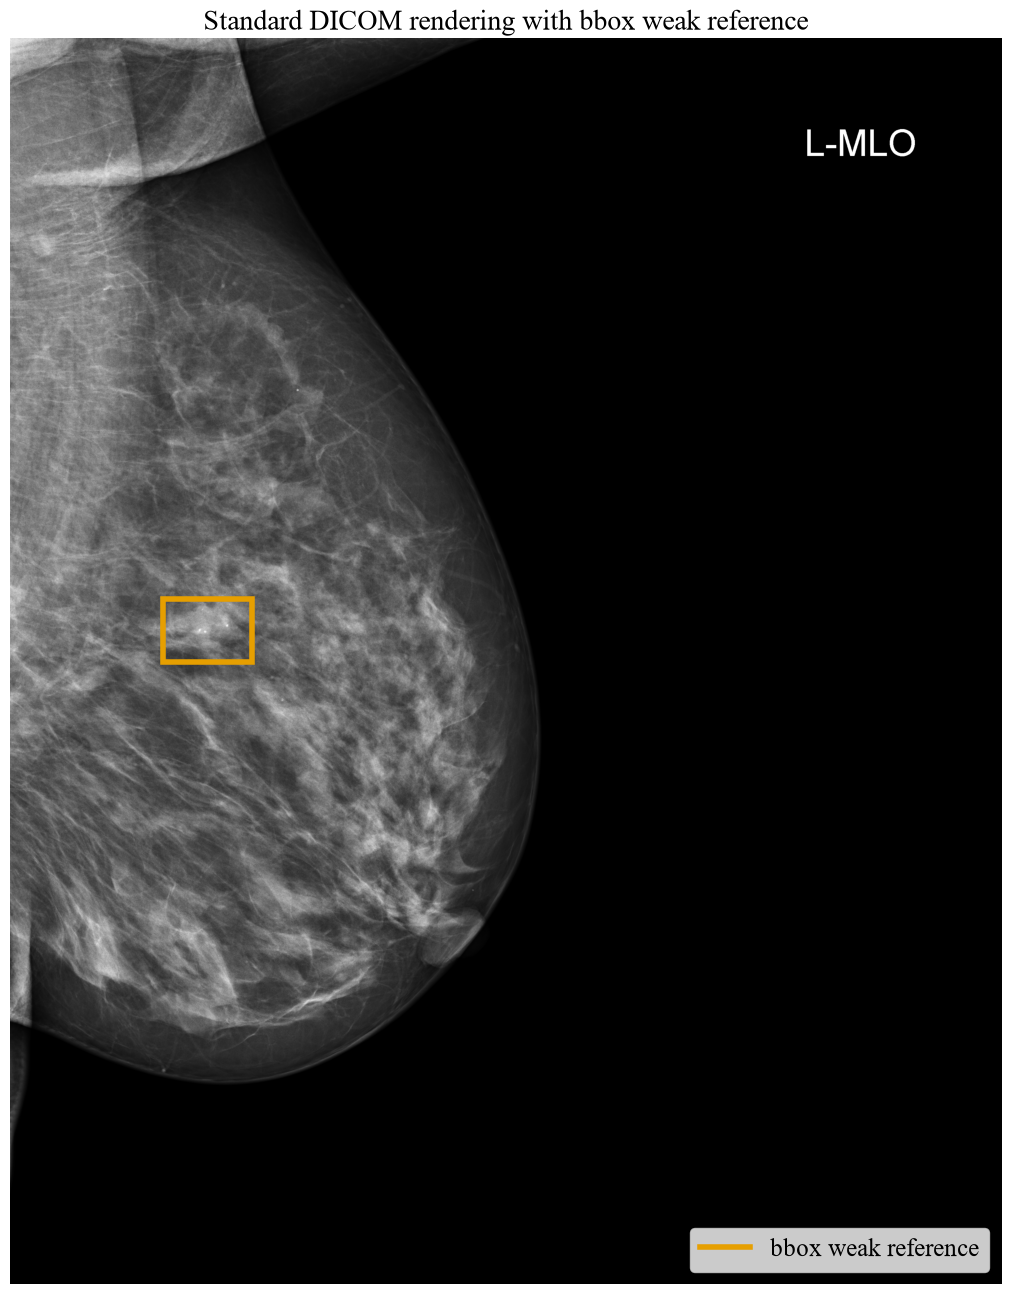

In [22]:
preview_boxes = boxes_from_manifest(preview_row)
fig, ax = plt.subplots(figsize=(10, 14), constrained_layout=True)
ax.imshow(preview_artifacts["rendered"]["image"], cmap="gray", vmin=0, vmax=1)

for xmin, ymin, xmax, ymax in preview_boxes:
    rectangle = plt.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        fill=False,
        edgecolor="#E69F00",
        linewidth=4,
    )
    ax.add_patch(rectangle)

legend_handle = plt.Line2D(
    [0],
    [0],
    color="#E69F00",
    linewidth=4,
    label="bbox weak reference",
)
ax.legend(handles=[legend_handle], loc="lower right", frameon=True)
ax.set_title("Standard DICOM rendering with bbox weak reference", fontsize=20)
ax.set_axis_off()
save_figure(fig, "F07_standard_dicom_render", preview_source_path)
display(fig)
plt.close(fig)

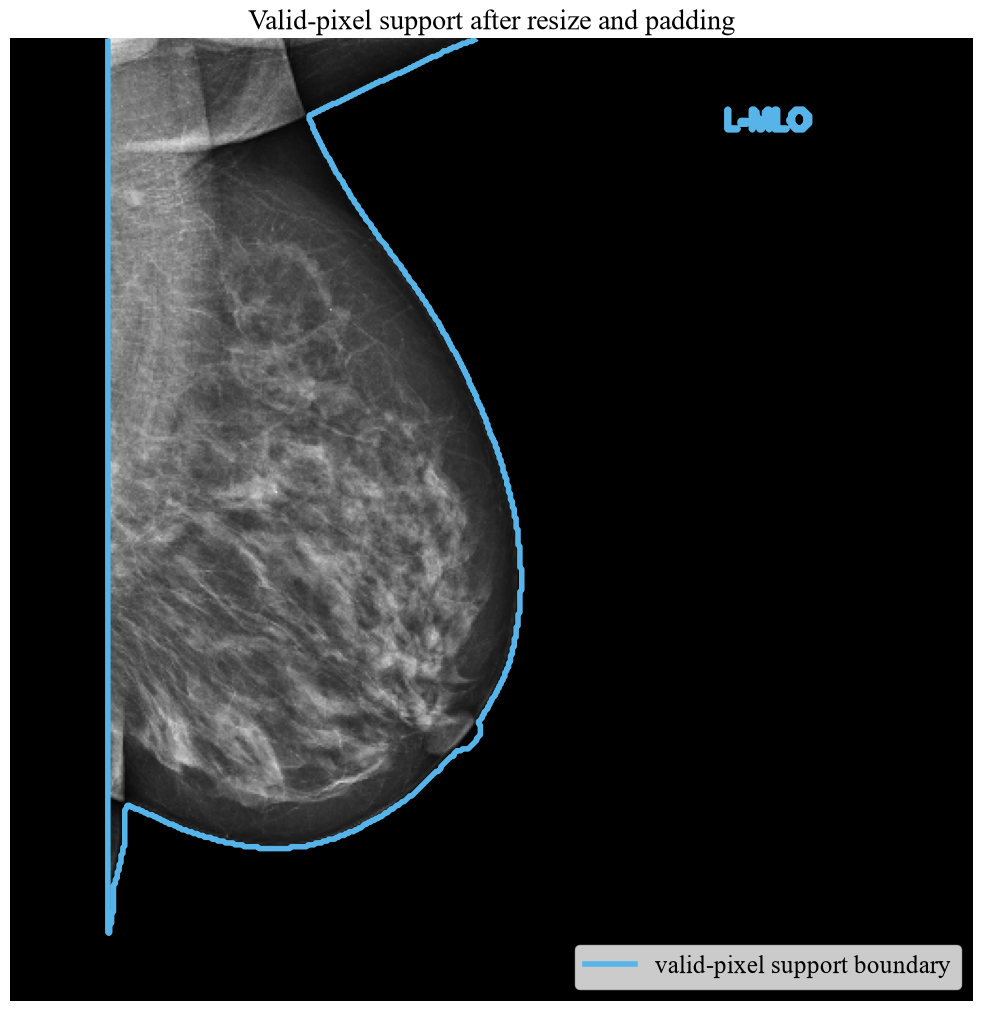

In [23]:
fig, ax = plt.subplots(figsize=(10, 10), constrained_layout=True)
ax.imshow(preview_artifacts["resized"], cmap="gray", vmin=0, vmax=1)
ax.contour(
    preview_artifacts["valid_mask"].astype(float),
    levels=[0.5],
    colors=["#56B4E9"],
    linewidths=4,
)
mask_handle = plt.Line2D(
    [0],
    [0],
    color="#56B4E9",
    linewidth=4,
    label="valid-pixel support boundary",
)
ax.legend(handles=[mask_handle], loc="lower right", frameon=True)
ax.set_title("Valid-pixel support after resize and padding", fontsize=20)
ax.set_axis_off()
save_figure(fig, "F08_valid_pixel_support", preview_source_path)
display(fig)
plt.close(fig)

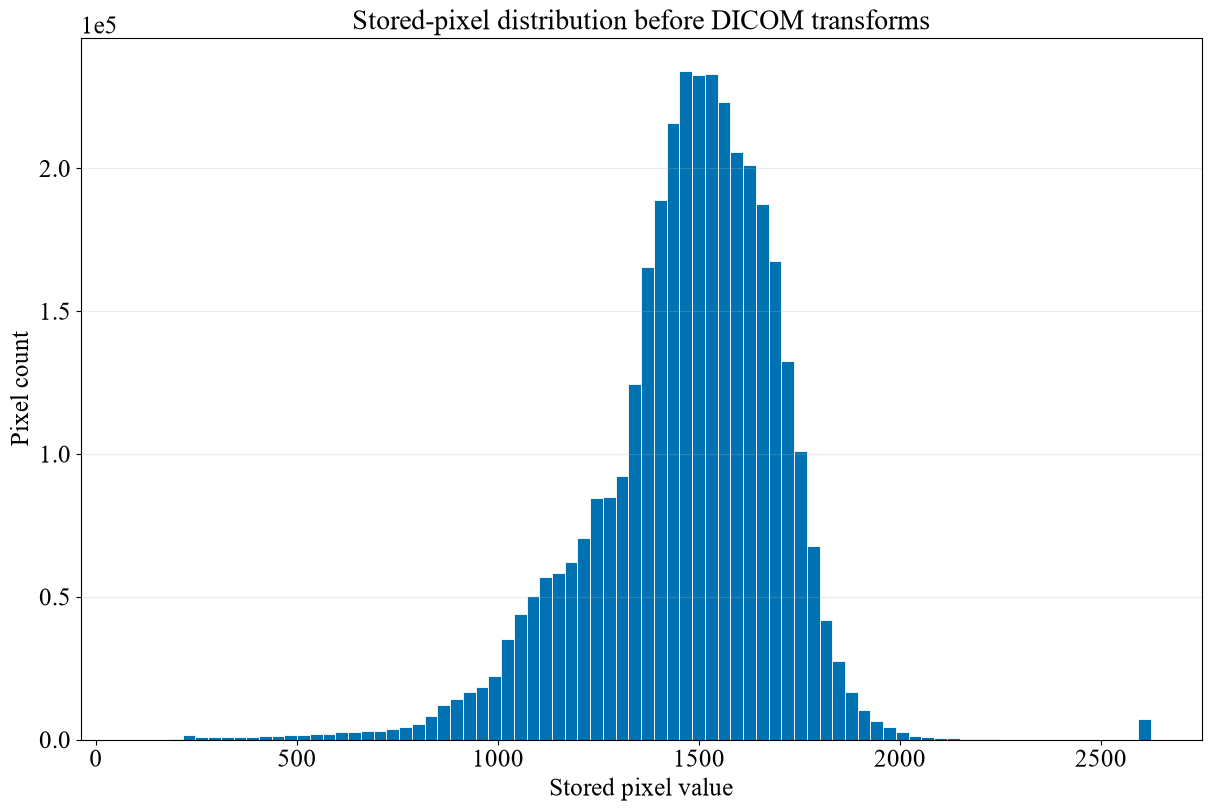

In [24]:
stored_values = preview_artifacts["rendered"]["stored"][
    preview_artifacts["rendered"]["valid_mask"]
]
fig, ax = plt.subplots(figsize=(12, 8), constrained_layout=True)
ax.hist(
    stored_values,
    bins=80,
    color="#0072B2",
    edgecolor="white",
    linewidth=0.6,
)
ax.set_title("Stored-pixel distribution before DICOM transforms", fontsize=20)
ax.set_xlabel("Stored pixel value")
ax.set_ylabel("Pixel count")
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.grid(axis="y", alpha=0.25)
save_figure(fig, "F09_stored_pixel_distribution", preview_source_path)
display(fig)
plt.close(fig)

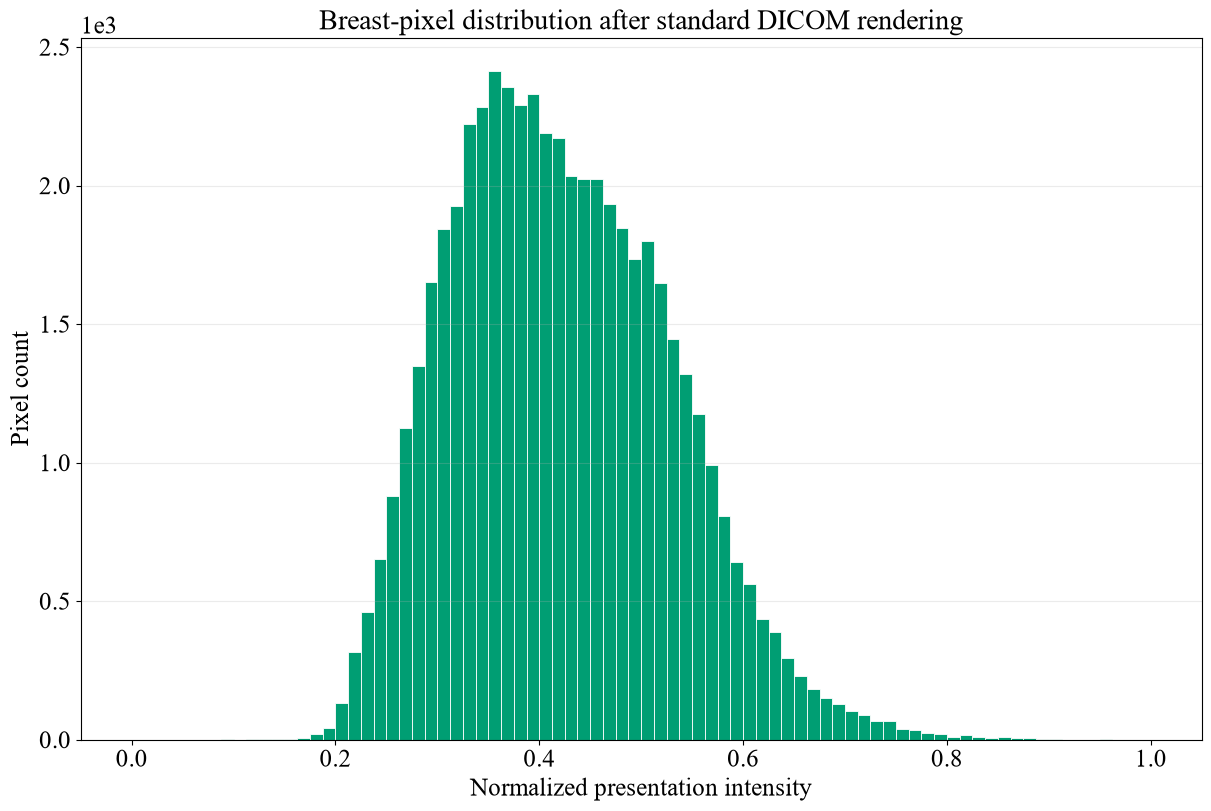

In [25]:
breast_values = preview_artifacts["resized"][preview_artifacts["breast_mask"]]
fig, ax = plt.subplots(figsize=(12, 8), constrained_layout=True)
ax.hist(
    breast_values,
    bins=80,
    range=(0.0, 1.0),
    color="#009E73",
    edgecolor="white",
    linewidth=0.6,
)
ax.set_title("Breast-pixel distribution after standard DICOM rendering", fontsize=20)
ax.set_xlabel("Normalized presentation intensity")
ax.set_ylabel("Pixel count")
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.grid(axis="y", alpha=0.25)
save_figure(fig, "F10_standard_presentation_distribution", preview_source_path)
display(fig)
plt.close(fig)

In [ ]:
FEATURE_TABLE_PATH = TABLE_DIR / "standard_dicom_features_train.csv"
feature_manifest_sha = sha256_file(MANIFEST_PATH)
reuse_feature_table = False

if FEATURE_TABLE_PATH.exists():
    cached_features = pd.read_csv(FEATURE_TABLE_PATH, low_memory=False)
    cache_matches = (
        "manifest_sha256" in cached_features.columns
        and cached_features.manifest_sha256.eq(feature_manifest_sha).all()
        and set(cached_features.image_id) == set(train_manifest.image_id)
    )
    if cache_matches:
        feature_table = cached_features
        reuse_feature_table = True

if not reuse_feature_table:
    feature_records = []
    ordered_train = train_manifest.sort_values("image_id")
    started_at = time.perf_counter()

    for position, (_, row) in enumerate(ordered_train.iterrows(), start=1):
        features_row, _ = extract_standard_features(row)
        features_row["manifest_sha256"] = feature_manifest_sha
        feature_records.append(features_row)

        if position % 100 == 0 or position == len(ordered_train):
            elapsed = time.perf_counter() - started_at
            print(f"Processed {position}/{len(ordered_train)} training images in {elapsed:.1f} s")

    feature_table = pd.DataFrame(feature_records)
    feature_table.to_csv(FEATURE_TABLE_PATH, index=False)

assert len(feature_table) == len(train_manifest)
assert feature_table.image_id.nunique() == len(feature_table)
assert feature_table.manifest_sha256.eq(feature_manifest_sha).all()
assert feature_table.drop(columns=["manifest_sha256"]).select_dtypes("number").notna().all().all()


In [27]:
def benjamini_hochberg(p_values: np.ndarray) -> np.ndarray:
    p_values = np.asarray(p_values, dtype=np.float64)
    order = np.argsort(p_values)
    ranked = p_values[order]
    ranks = np.arange(1, len(ranked) + 1, dtype=np.float64)
    adjusted_ranked = ranked * len(ranked) / ranks
    adjusted_ranked = np.minimum.accumulate(adjusted_ranked[::-1])[::-1]
    adjusted = np.empty_like(adjusted_ranked)
    adjusted[order] = np.clip(adjusted_ranked, 0.0, 1.0)
    return adjusted

In [28]:
analysis_features = [
    "intensity_mean",
    "intensity_std",
    "intensity_iqr",
    "intensity_skew",
    "intensity_kurtosis",
    "intensity_entropy",
    "lbp_entropy",
    "lbp_uniformity",
    "gradient_mean",
    "gradient_q95",
    "glcm_contrast",
    "glcm_dissimilarity",
    "glcm_homogeneity",
    "glcm_energy",
    "glcm_correlation",
    "breast_area_fraction",
    "breast_eccentricity",
    "breast_solidity",
    "breast_extent",
    "breast_perimeter_normalized",
    "breast_axis_ratio",
    "breast_area_mm2",
]

In [29]:
study_has_target = feature_table.groupby("study_id").label.max()
target_study_features = (
    feature_table.loc[feature_table.label.eq(1)]
    .groupby("study_id")[analysis_features]
    .median()
)
control_study_ids = study_has_target.index[study_has_target.eq(0)]
control_study_features = (
    feature_table.loc[feature_table.study_id.isin(control_study_ids)]
    .groupby("study_id")[analysis_features]
    .median()
)

assert target_study_features.index.is_unique
assert control_study_features.index.is_unique
assert set(target_study_features.index).isdisjoint(control_study_features.index)
print(
    f"Independent training studies: {len(target_study_features)} target, "
    f"{len(control_study_features)} other-finding control"
)

In [30]:
def bootstrap_median_difference_ci(
    target_values: np.ndarray,
    control_values: np.ndarray,
    rng: np.random.Generator,
    n_resamples: int = 2000,
) -> tuple[float, float]:
    target_draws = rng.choice(
        target_values,
        size=(n_resamples, target_values.size),
        replace=True,
    )
    control_draws = rng.choice(
        control_values,
        size=(n_resamples, control_values.size),
        replace=True,
    )
    differences = np.median(target_draws, axis=1) - np.median(control_draws, axis=1)
    lower, upper = np.quantile(differences, [0.025, 0.975])
    return float(lower), float(upper)

In [31]:
rng = np.random.default_rng(20260727)
comparison_records = []

for feature_name in analysis_features:
    target_values = target_study_features[feature_name].dropna().to_numpy()
    control_values = control_study_features[feature_name].dropna().to_numpy()
    test = stats.mannwhitneyu(
        target_values,
        control_values,
        alternative="two-sided",
        method="asymptotic",
    )
    rank_biserial = 2.0 * test.statistic / (target_values.size * control_values.size) - 1.0
    ci_lower, ci_upper = bootstrap_median_difference_ci(
        target_values,
        control_values,
        rng,
    )
    comparison_records.append(
        {
            "feature": feature_name,
            "target_studies": target_values.size,
            "control_studies": control_values.size,
            "target_median": float(np.median(target_values)),
            "control_median": float(np.median(control_values)),
            "median_difference": float(np.median(target_values) - np.median(control_values)),
            "median_difference_ci_lower": ci_lower,
            "median_difference_ci_upper": ci_upper,
            "rank_biserial": float(rank_biserial),
            "p_value": float(test.pvalue),
        }
    )

texture_statistics = pd.DataFrame(comparison_records)
texture_statistics["q_value_bh"] = benjamini_hochberg(
    texture_statistics.p_value.to_numpy()
)
texture_statistics["exploratory_fdr_0_05"] = texture_statistics.q_value_bh.lt(0.05)
texture_statistics = texture_statistics.sort_values("q_value_bh")

TEXTURE_STATS_PATH = TABLE_DIR / "texture_group_statistics.csv"
texture_statistics.to_csv(TEXTURE_STATS_PATH, index=False)
display(texture_statistics.head(10))

,feature,target_studies,control_studies,target_median,control_median,median_difference,median_difference_ci_lower,median_difference_ci_upper,rank_biserial,p_value,q_value_bh,exploratory_fdr_0_05
4,intensity_kurtosis,88,313,0.071095,-0.021815,0.092910,-0.004205,0.227853,0.172451,0.013439,0.295648,False
1,intensity_std,88,313,0.097393,0.099281,-0.001889,-0.006389,0.001745,-0.087642,0.209114,0.669989,False
3,intensity_skew,88,313,0.394978,0.350011,0.044967,-0.037977,0.134148,0.073047,0.295211,0.669989,False
2,intensity_iqr,88,313,0.132531,0.133731,-0.001200,-0.007950,0.003836,-0.093596,0.179800,0.669989,False
5,intensity_entropy,88,313,4.618069,4.648814,-0.030744,-0.067924,0.024406,-0.099913,0.152161,0.669989,False
11,glcm_dissimilarity,88,313,1.954506,1.965929,-0.011424,-0.083440,0.068149,-0.060195,0.388415,0.669989,False
9,gradient_q95,88,313,0.096798,0.098966,-0.002169,-0.006170,0.003377,-0.059251,0.395903,0.669989,False
8,gradient_mean,88,313,0.044763,0.045098,-0.000335,-0.002488,0.001377,-0.061937,0.374821,0.669989,False
14,glcm_correlation,88,313,0.621539,0.640632,-0.019093,-0.031450,0.001621,-0.066439,0.341085,0.669989,False
13,glcm_energy,88,313,0.115649,0.113904,0.001745,-0.002649,0.005828,0.085391,0.221053,0.669989,False


In [32]:
def binary_composition(
    frame: pd.DataFrame,
    analysis_name: str,
    positive_mask: pd.Series,
    positive_label: str,
    negative_label: str,
) -> list[dict]:
    total = len(frame)
    positive_count = int(positive_mask.sum())
    negative_count = total - positive_count

    return [
        {
            "analysis": analysis_name,
            "category": positive_label,
            "count": positive_count,
            "percentage": 100.0 * positive_count / total,
        },
        {
            "analysis": analysis_name,
            "category": negative_label,
            "count": negative_count,
            "percentage": 100.0 * negative_count / total,
        },
    ]

In [33]:
composition_specs = [
    (
        "Bits stored",
        train_acquisition.bits_stored.eq(12),
        "12-bit",
        "16-bit",
    ),
    (
        "Photometric",
        train_acquisition.photometric_interpretation.eq("MONOCHROME2"),
        "MONOCHROME2",
        "MONOCHROME1",
    ),
    (
        "VOI LUT Sequence",
        train_acquisition.voi_lut_sequence_present.eq(True),
        "present",
        "absent",
    ),
    (
        "Padding range",
        train_acquisition.pixel_padding_range_limit.notna(),
        "present",
        "absent",
    ),
]

header_records = []
for analysis_name, mask, positive_label, negative_label in composition_specs:
    header_records.extend(
        binary_composition(
            train_acquisition,
            analysis_name,
            mask,
            positive_label,
            negative_label,
        )
    )

header_summary = pd.DataFrame(header_records)
HEADER_SUMMARY_PATH = TABLE_DIR / "standard_dicom_header_summary_train.csv"
header_summary.to_csv(HEADER_SUMMARY_PATH, index=False)
display(header_summary)

,analysis,category,count,percentage
0,Bits stored,12-bit,550,73.825503
1,Bits stored,16-bit,195,26.174497
2,Photometric,MONOCHROME2,637,85.503356
3,Photometric,MONOCHROME1,108,14.496644
4,VOI LUT Sequence,present,550,73.825503
5,VOI LUT Sequence,absent,195,26.174497
6,Padding range,present,87,11.677852
7,Padding range,absent,658,88.322148


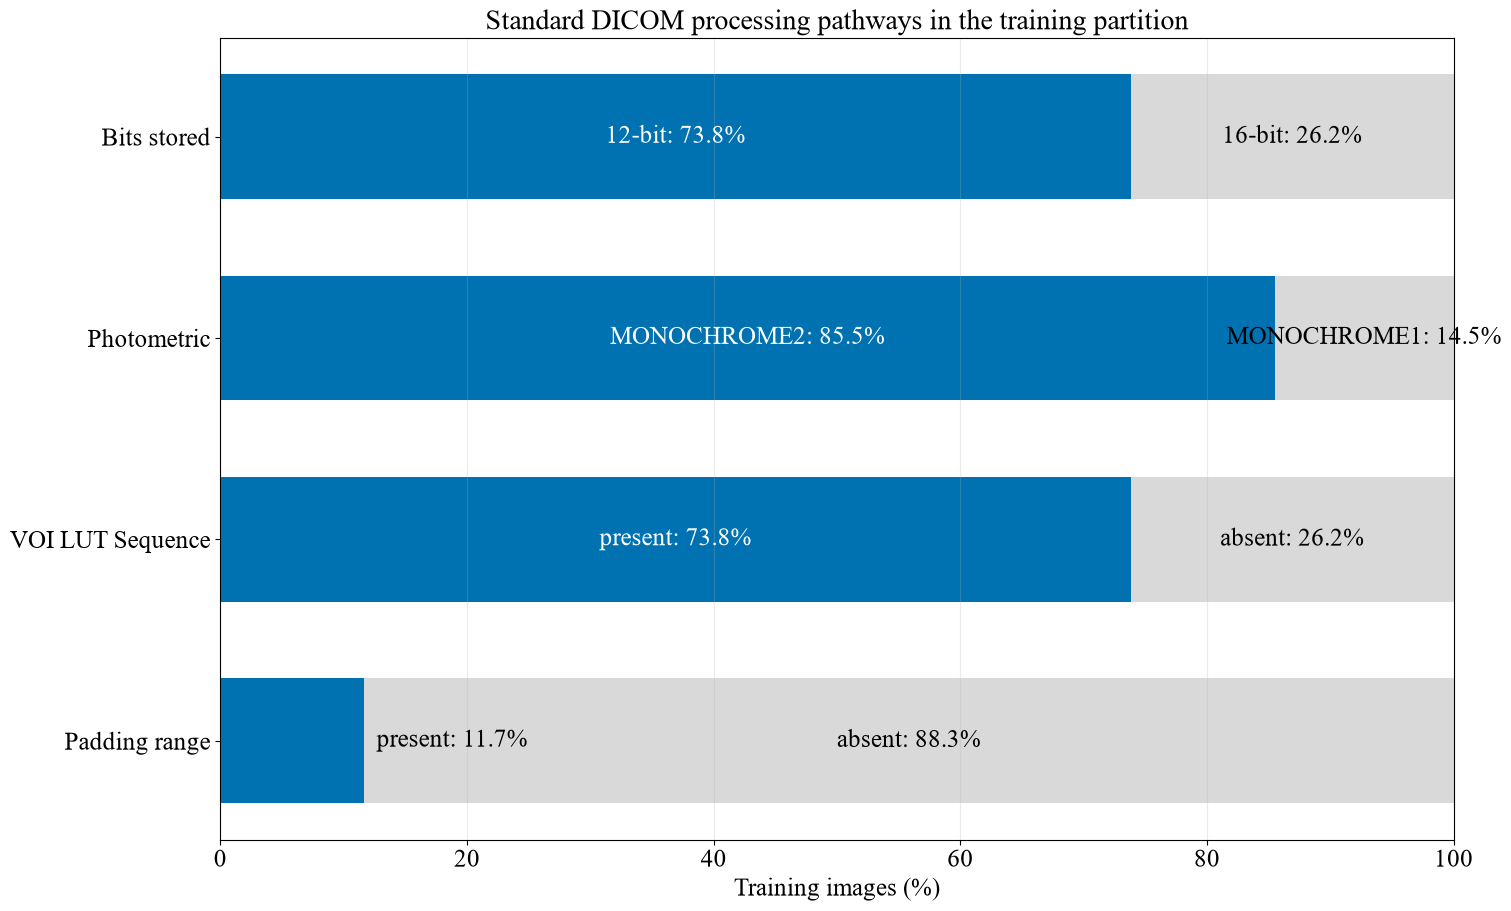

In [34]:
analysis_order = [
    "Bits stored",
    "Photometric",
    "VOI LUT Sequence",
    "Padding range",
]
fig, ax = plt.subplots(figsize=(15, 9), constrained_layout=True)

for position, analysis_name in enumerate(analysis_order):
    rows = header_summary.loc[header_summary.analysis.eq(analysis_name)].reset_index(drop=True)
    left_width = rows.loc[0, "percentage"]
    right_width = rows.loc[1, "percentage"]
    ax.barh(position, left_width, color="#0072B2", height=0.62)
    ax.barh(position, right_width, left=left_width, color="#D9D9D9", height=0.62)
    left_inside = left_width >= 20
    ax.text(
        left_width / 2 if left_inside else left_width + 1.0,
        position,
        f"{rows.loc[0, 'category']}: {left_width:.1f}%",
        ha="center" if left_inside else "left",
        va="center",
        color="white" if left_inside else "black",
        fontsize=18,
    )
    ax.text(
        left_width + right_width / 2,
        position,
        f"{rows.loc[1, 'category']}: {right_width:.1f}%",
        ha="center",
        va="center",
        color="black",
        fontsize=18,
    )

ax.set_yticks(range(len(analysis_order)), labels=analysis_order)
ax.set_xlim(0, 100)
ax.set_xlabel("Training images (%)")
ax.set_title("Standard DICOM processing pathways in the training partition", fontsize=20)
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.25)
save_figure(fig, "F11_standard_dicom_pathways", HEADER_SUMMARY_PATH)
display(fig)
plt.close(fig)

In [35]:
correlation_features = [
    "intensity_std",
    "intensity_entropy",
    "lbp_entropy",
    "gradient_q95",
    "glcm_contrast",
    "glcm_homogeneity",
    "breast_area_fraction",
    "breast_solidity",
]
correlation_labels = {
    "intensity_std": "Intensity SD",
    "intensity_entropy": "Intensity entropy",
    "lbp_entropy": "LBP entropy",
    "gradient_q95": "Gradient Q95",
    "glcm_contrast": "GLCM contrast",
    "glcm_homogeneity": "GLCM homogeneity",
    "breast_area_fraction": "Breast area fraction",
    "breast_solidity": "Breast solidity",
}

study_correlation_input = pd.concat(
    [target_study_features, control_study_features],
    axis=0,
).loc[:, correlation_features]
feature_correlation = study_correlation_input.corr(method="spearman")
CORRELATION_PATH = TABLE_DIR / "study_feature_spearman_correlation.csv"
feature_correlation.to_csv(CORRELATION_PATH)
display(feature_correlation.round(3))

,intensity_std,intensity_entropy,lbp_entropy,gradient_q95,glcm_contrast,glcm_homogeneity,breast_area_fraction,breast_solidity
intensity_std,1.000,0.966,0.569,0.695,0.770,-0.642,-0.318,-0.374
intensity_entropy,0.966,1.000,0.614,0.738,0.801,-0.721,-0.285,-0.398
lbp_entropy,0.569,0.614,1.000,0.582,0.605,-0.613,-0.129,-0.219
gradient_q95,0.695,0.738,0.582,1.000,0.949,-0.923,-0.215,-0.431
glcm_contrast,0.770,0.801,0.605,0.949,1.000,-0.944,-0.243,-0.412
glcm_homogeneity,-0.642,-0.721,-0.613,-0.923,-0.944,1.000,0.194,0.384
breast_area_fraction,-0.318,-0.285,-0.129,-0.215,-0.243,0.194,1.000,0.310
breast_solidity,-0.374,-0.398,-0.219,-0.431,-0.412,0.384,0.310,1.000


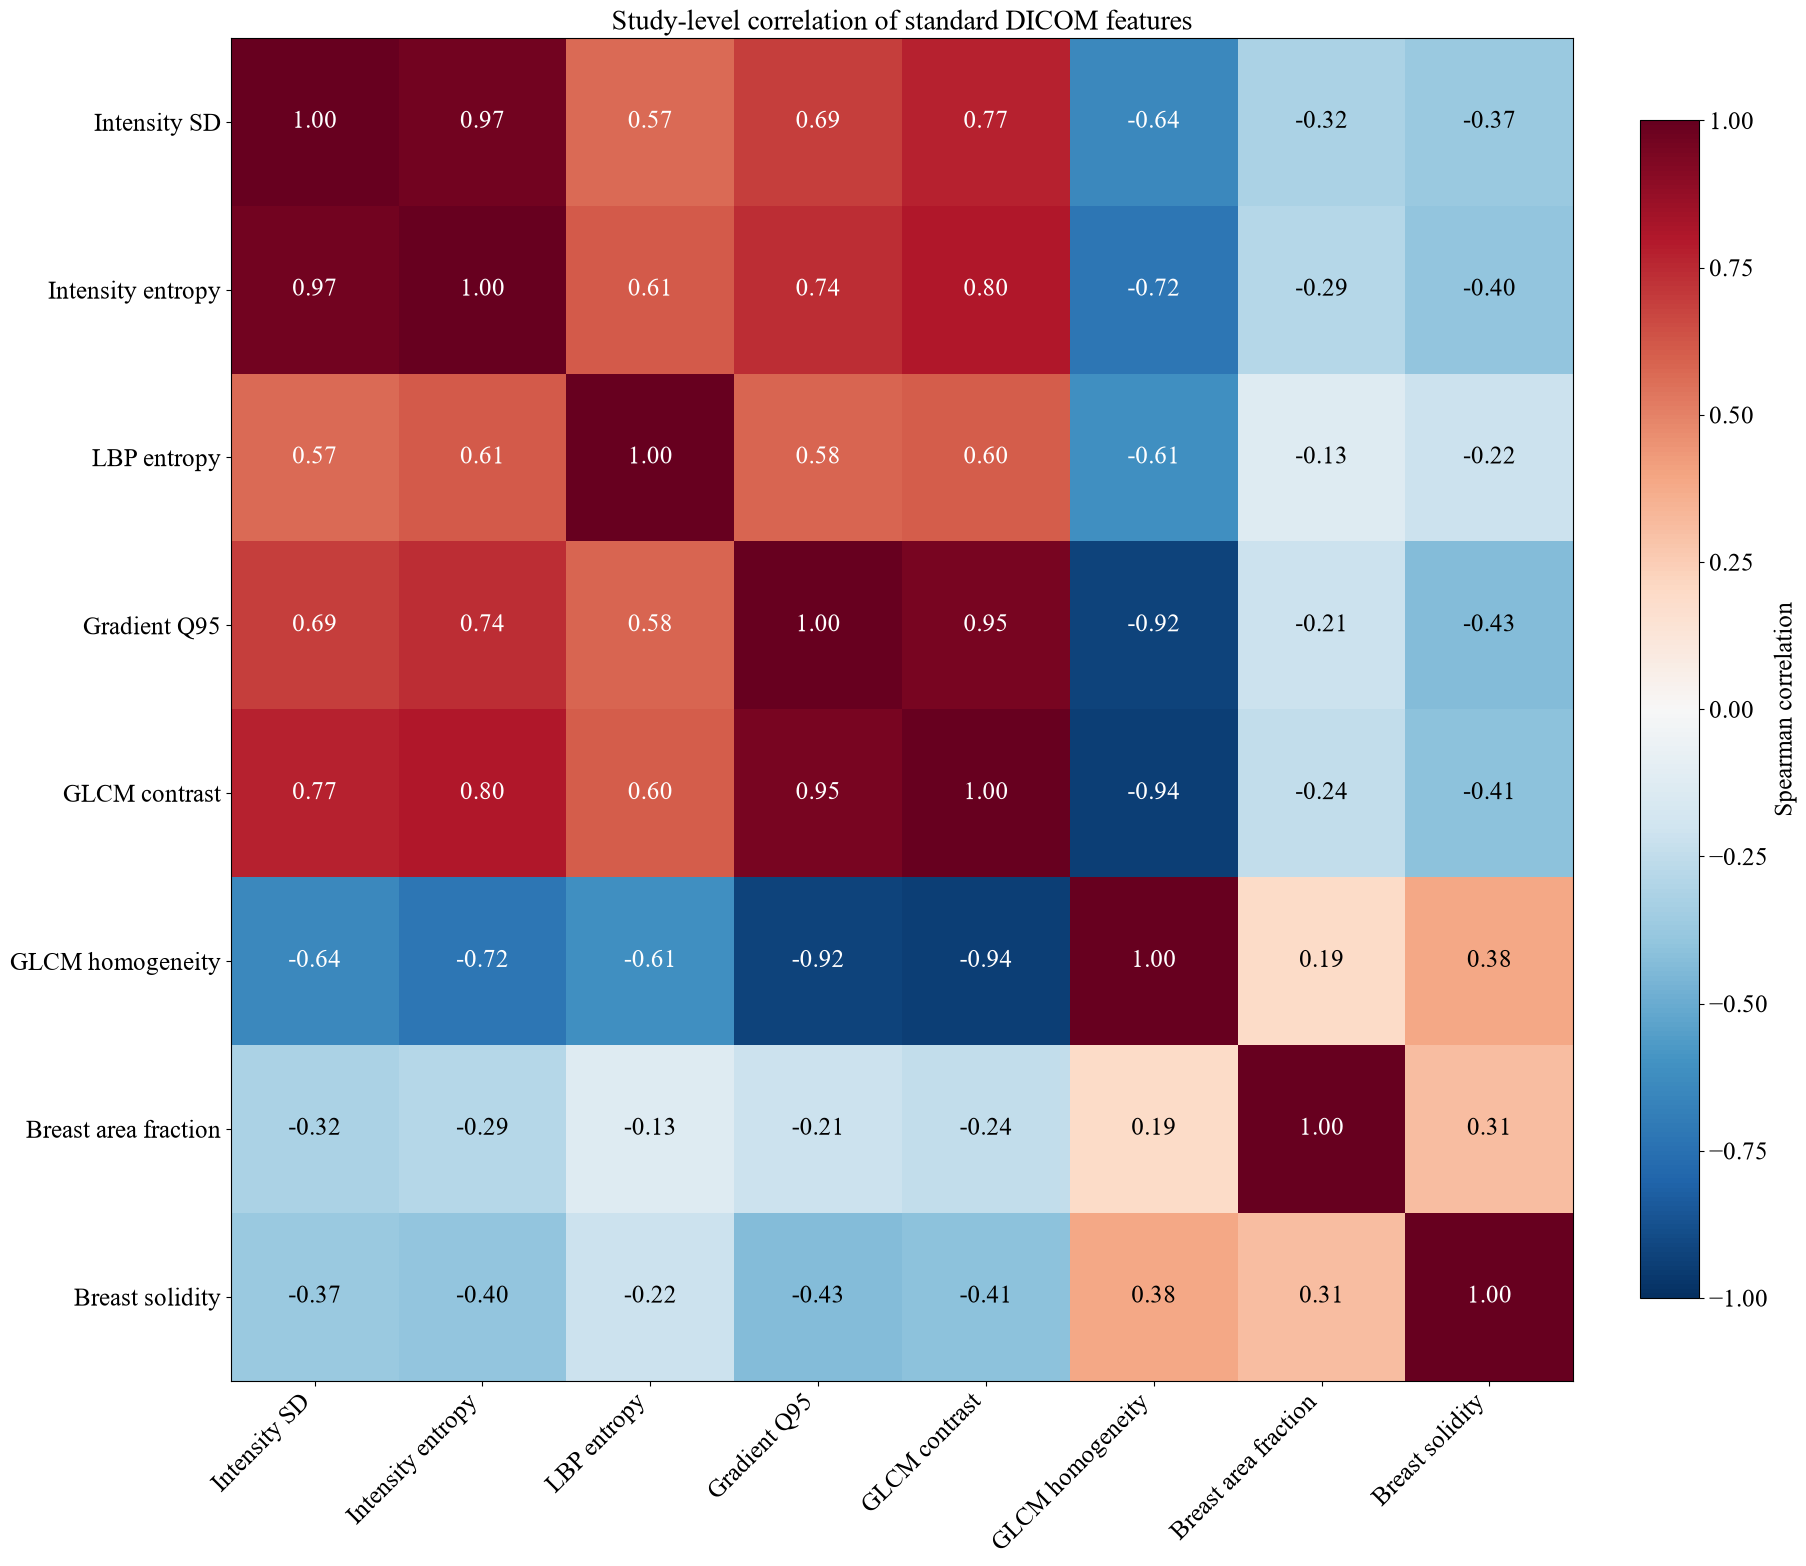

In [36]:
matrix = feature_correlation.to_numpy()
labels = [correlation_labels[name] for name in correlation_features]
fig, ax = plt.subplots(figsize=(18, 16), constrained_layout=True)
image_handle = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(labels)), labels=labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels=labels)
for row_index in range(matrix.shape[0]):
    for column_index in range(matrix.shape[1]):
        value = matrix[row_index, column_index]
        text_color = "white" if abs(value) >= 0.55 else "black"
        ax.text(
            column_index,
            row_index,
            f"{value:.2f}",
            ha="center",
            va="center",
            color=text_color,
            fontsize=18,
        )

colorbar = fig.colorbar(image_handle, ax=ax, shrink=0.82)
colorbar.set_label("Spearman correlation")
colorbar.ax.tick_params(labelsize=18)
ax.set_title("Study-level correlation of standard DICOM features", fontsize=20)
save_figure(fig, "F12_study_feature_correlation", CORRELATION_PATH)
display(fig)
plt.close(fig)

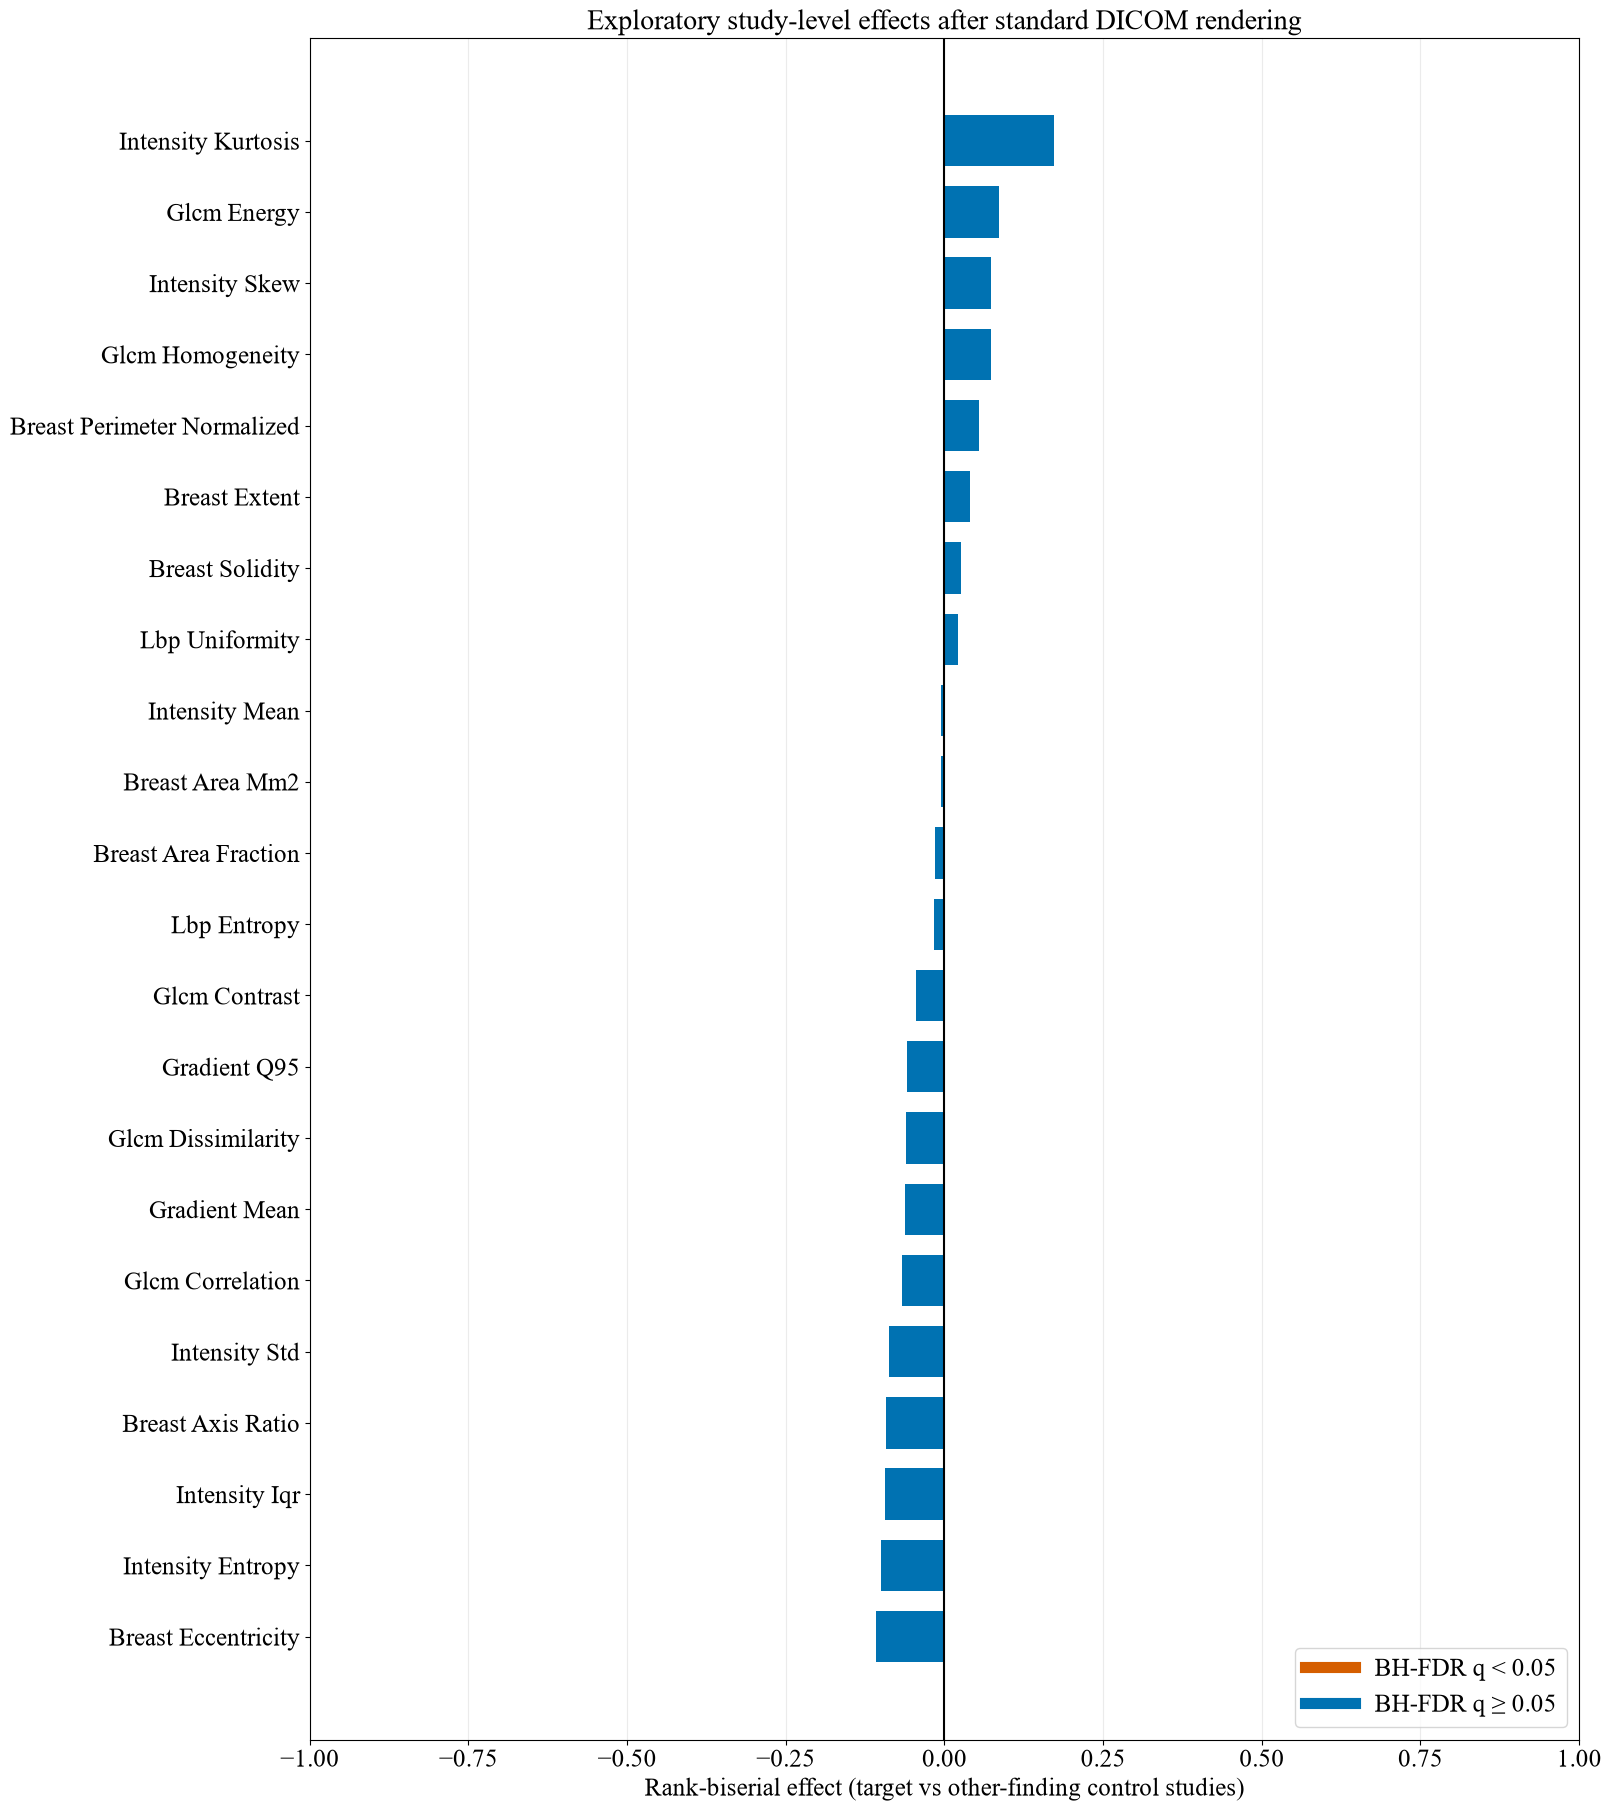

In [37]:
effect_plot = texture_statistics.sort_values("rank_biserial").copy()
effect_labels = [name.replace("_", " ").title() for name in effect_plot.feature]
effect_colors = np.where(
    effect_plot.exploratory_fdr_0_05,
    "#D55E00",
    "#0072B2",
)

fig, ax = plt.subplots(figsize=(16, 18), constrained_layout=True)
positions = np.arange(len(effect_plot))
ax.barh(positions, effect_plot.rank_biserial, color=effect_colors, height=0.72)
ax.axvline(0.0, color="black", linewidth=1.5)
ax.set_yticks(positions, labels=effect_labels)
ax.set_xlim(-1.0, 1.0)
ax.set_xlabel("Rank-biserial effect (target vs other-finding control studies)")
ax.set_title("Exploratory study-level effects after standard DICOM rendering", fontsize=20)
ax.grid(axis="x", alpha=0.25)
legend_handles = [
    plt.Line2D([0], [0], color="#D55E00", linewidth=8, label="BH-FDR q < 0.05"),
    plt.Line2D([0], [0], color="#0072B2", linewidth=8, label="BH-FDR q ≥ 0.05"),
]
ax.legend(handles=legend_handles, loc="lower right", frameon=True)
save_figure(fig, "F13_exploratory_feature_effects", TEXTURE_STATS_PATH)
display(fig)
plt.close(fig)

In [38]:
top_feature = texture_statistics.iloc[0].feature
target_top_values = target_study_features[top_feature].dropna()
control_top_values = control_study_features[top_feature].dropna()

top_feature_values = pd.concat(
    [
        target_top_values.rename("value").to_frame().assign(group="Target study"),
        control_top_values.rename("value").to_frame().assign(group="Other-finding control study"),
    ]
).reset_index()
top_feature_values["feature"] = top_feature
top_feature_values["selection_rule"] = "lowest BH-FDR q value in training-only exploratory analysis"
TOP_FEATURE_PATH = TABLE_DIR / "top_ranked_feature_study_values.csv"
top_feature_values.to_csv(TOP_FEATURE_PATH, index=False)

display(
    texture_statistics.loc[
        texture_statistics.feature.eq(top_feature),
        ["feature", "rank_biserial", "p_value", "q_value_bh"],
    ]
)

,feature,rank_biserial,p_value,q_value_bh
4,intensity_kurtosis,0.172451,0.013439,0.295648


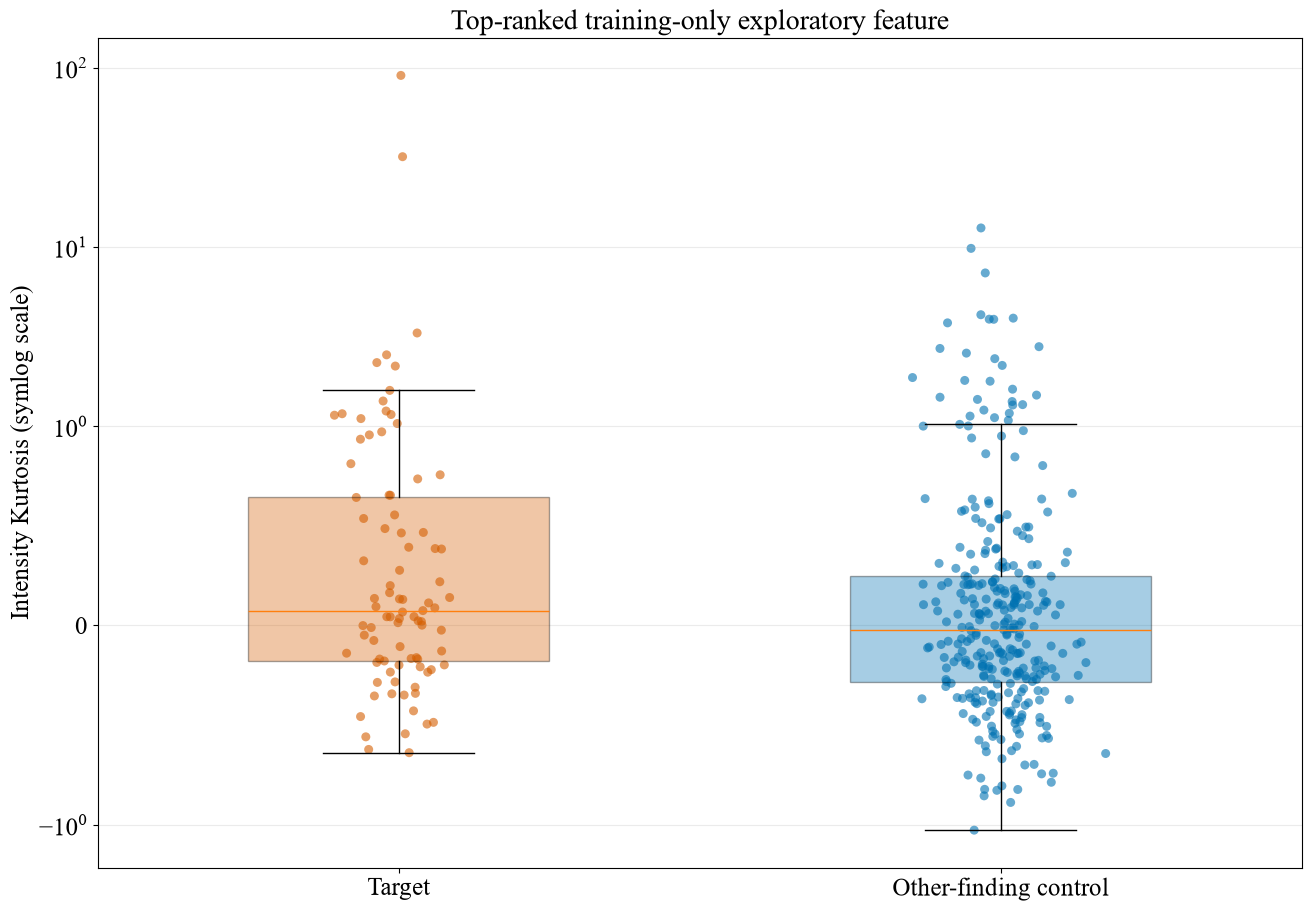

In [39]:
plot_rng = np.random.default_rng(20260727)
fig, ax = plt.subplots(figsize=(13, 9), constrained_layout=True)
boxplot = ax.boxplot(
    [target_top_values.to_numpy(), control_top_values.to_numpy()],
    positions=[1, 2],
    widths=0.5,
    patch_artist=True,
    showfliers=False,
    tick_labels=["Target", "Other-finding control"],
)
for patch, color in zip(boxplot["boxes"], ["#D55E00", "#0072B2"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.35)

for position, values, color in [
    (1, target_top_values.to_numpy(), "#D55E00"),
    (2, control_top_values.to_numpy(), "#0072B2"),
]:
    jitter = plot_rng.normal(position, 0.055, size=values.size)
    ax.scatter(
        jitter,
        values,
        s=42,
        alpha=0.60,
        color=color,
        edgecolors="none",
    )

ax.set_yscale("symlog", linthresh=1.0, linscale=1.0)
ax.set_ylabel(f"{top_feature.replace('_', ' ').title()} (symlog scale)")
ax.set_title("Top-ranked training-only exploratory feature", fontsize=20)
ax.grid(axis="y", alpha=0.25)
save_figure(fig, "F14_top_ranked_exploratory_feature", TOP_FEATURE_PATH)
display(fig)
plt.close(fig)

In [40]:
PREPROCESSING_CONFIG_PATH = CONFIG_DIR / "standard_dicom_preprocessing.json"
preprocessing_config = {
    "version": "1.0.0",
    "scope": "canonical mammography DICOM rendering and deterministic model-input preparation",
    "primary_model_input_size": [1024, 1024],
    "eda_feature_size": [512, 512],
    "ordered_steps": [
        "decode stored pixels",
        "mask inclusive Pixel Padding Value to Pixel Padding Range Limit in stored domain",
        "apply Modality LUT or rescale",
        "apply VOI LUT with prefer_lut=true",
        "apply Presentation LUT or documented MONOCHROME polarity fallback",
        "normalize finite valid presentation pixels to [0, 1]",
        "aspect-preserving resize and zero padding",
        "apply the identical affine transform to bbox coordinates",
    ],
    "primary_input_exclusions": [
        "histogram equalization",
        "CLAHE",
        "percentile clipping",
        "bbox-conditioned preprocessing",
    ],
    "bbox_role": "weak localization reference only; never used for rendering or breast-mask extraction",
    "library_versions": {
        "python": sys.version.split()[0],
        "pydicom": pydicom.__version__,
        "numpy": np.__version__,
        "opencv": cv2.__version__,
        "matplotlib": mpl.__version__,
    },
    "input_manifest_sha256": feature_manifest_sha,
}

In [ ]:
PREPROCESSING_CONFIG_PATH.write_text(
    json.dumps(preprocessing_config, indent=2, ensure_ascii=False),
    encoding="utf-8",
)
